In [3]:
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


In [26]:
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
import torch.nn as nn
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader,Dataset,Subset
from sklearn.metrics import accuracy_score,precision_score,confusion_matrix,recall_score, f1_score
import zipfile
from sklearn.model_selection import train_test_split
import time
import copy
import torch.optim as optim

In [8]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

Device: cuda


In [11]:
zip_path = '/content/drive/MyDrive/realwaste.zip'
extract_path = '/content/dataset'
try:
  with zipfile.ZipFile(zip_path, 'r') as zip_ref:
      zip_ref.extractall(extract_path)
      print(f'Extraction Completed')
except FileNotFoundError:
  print(f'File Not Found')



Extraction Completed


In [13]:
#---------------Transforming the Dataset to have 64X64 Images-------------------------
data_transforms = transforms.Compose(
    [transforms.Resize((64,64)),
     transforms.ToTensor(),
     transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])]
)

In [15]:
Data_Dir = '/content/dataset/realwaste-main/RealWaste'

dataset = datasets.ImageFolder(Data_Dir, transform=data_transforms)
num_of_classes = len(dataset.classes)
print(f'Number of Classes: {num_of_classes}')
print(f'length: {len(dataset)}')

Number of Classes: 9
length: 4752


In [18]:
indices = list(range(len(dataset)))
targets = dataset.targets
BATCH_SIZE = 32

train_idx, temp_idx, train_targets, temp_targets = train_test_split(
    indices, targets, test_size=0.30, random_state=42, stratify=targets)

val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, random_state=42, stratify=temp_targets)

train_dataset = Subset(dataset, train_idx)
val_dataset = Subset(dataset, val_idx)
test_dataset = Subset(dataset, test_idx)

dataloaders = {
    'train': DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True),
    'val': DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False),
    'test': DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
}
print(f'DataLoading Completed...')

DataLoading Completed...


In [62]:
class Standard_Model(nn.Module):
  def __init__(self,num_of_classes):
    super(Standard_Model,self).__init__()
    self.features = nn.Sequential(
        nn.Conv2d(3, 16, kernel_size = 3, padding = 1),
        nn.ReLU(inplace = True),
        nn.MaxPool2d(kernel_size = 2, stride = 2),             # Here we have 32*32 and channels 16
        nn.Conv2d(16, 32,kernel_size = 3, padding = 1),        # Here channels become 32
        nn.ReLU(inplace = True),
        nn.MaxPool2d(kernel_size = 2, stride = 2),             # Here We have 16*16 and channels 32
        nn.Conv2d(32, 64, kernel_size = 3, padding = 1),       # Here Channels become 64
        nn.ReLU(inplace = True),
        nn.MaxPool2d(kernel_size = 2, stride = 2)             # Here We have 8*8 and channels 64

    )

    self.classifier = nn.Sequential(
        nn.Flatten(),                   #Here we have 8*8*64
        nn.Linear(64*8*8, 128),
        nn.ReLU(inplace = True),
        nn.Linear(128, num_of_classes)   # Classify into one class within 9 classes
    )

  def forward(self,x):
    x = self.features(x)
    x = self.classifier(x)
    return x



In [50]:
class DepthWiseSeperableConvolution(nn.Module):
  def __init__(self, in_channels, out_channels, stride = 1):
    super(DepthWiseSeperableConvolution, self).__init__()
    self.depthwise = nn.Conv2d(
        in_channels,
        in_channels,
        kernel_size = 3,
        stride = stride,
        padding = 1,
        groups = in_channels,
        bias = False
    )
    self.pointwise = nn.Conv2d(
        in_channels,
        out_channels,
        kernel_size = 1,
        bias = False
    )
    self.bn = nn.BatchNorm2d(out_channels)
    self.relu = nn.ReLU(inplace = True)

  def forward(self,x):
    x = self.depthwise(x)
    x = self.pointwise(x)
    x = self.bn(x)
    return self.relu(x)


In [63]:
class LightWeightModel(nn.Module):
  def __init__(self, num_classes):
        super(LightWeightModel, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1, stride=2, bias=False), # 32x32
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            DepthWiseSeperableConvolution(16, 32, stride=2), # 16x16
            DepthWiseSeperableConvolution(32, 64, stride=2), # 8x8
            DepthWiseSeperableConvolution(64, 64, stride=1), # 8x8
            nn.AdaptiveAvgPool2d((1, 1)) # 1x1
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64, num_classes)
        )

  def forward(self, x):
      x = self.features(x)
      x = self.classifier(x)
      return x



In [37]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [38]:
def get_model_size_mb(model):
    param_size = 0
    for param in model.parameters():
        param_size += param.nelement() * param.element_size()
    buffer_size = 0
    for buffer in model.buffers():
        buffer_size += buffer.nelement() * buffer.element_size()
    size_all_mb = (param_size + buffer_size) / 1024**2
    return size_all_mb

In [72]:
def train_model(model, dataloaders, criterion, optimizer, num_of_epochs = 30):
  history = {'train_loss':[], 'train_acc':[], 'val_loss':[], 'val_acc':[]}
  since = time.perf_counter()

  best_model_wts = copy.deepcopy(model.state_dict())
  best_acc = 0.0
  epoch_times = []

  for epoch in range(num_of_epochs):
    print(f'Epoch {epoch+1}/{num_of_epochs}')
    print('-' * 10)
    epoch_start_time = time.perf_counter()

    for phase in ['train','val']:
      if phase == 'train':
        model.train()
      else:
        model.eval()

      running_loss = 0.0
      running_corrects = 0

      for inputs, labels in dataloaders[phase]:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()

        with torch.set_grad_enabled(phase == 'train'):
          outputs = model(inputs)
          temp, preds = torch.max(outputs, 1)
          loss = criterion(outputs, labels)

          if phase == 'train':
            loss.backward()
            optimizer.step()
          running_loss += loss.item() * inputs.size(0)
          running_corrects += torch.sum(preds == labels.data)

      epoch_loss = running_loss / len(dataloaders[phase].dataset)
      epoch_acc = running_corrects.double() / len(dataloaders[phase].dataset)

      history[f'{phase}_loss'].append(epoch_loss)
      history[f'{phase}_acc'].append(epoch_acc.item())

      if phase == 'val' and epoch_acc > best_acc:
          best_acc = epoch_acc
          best_model_wts = copy.deepcopy(model.state_dict())

    epoch_times.append(time.perf_counter() - epoch_start_time)

  time_elapsed = time.perf_counter() - since
  avg_epoch_time = sum(epoch_times) / len(epoch_times)

  model.load_state_dict(best_model_wts)
  return model, history, avg_epoch_time

In [54]:
def evaluate_model(model, dataloader):
  model.eval()
  all_predictions = []
  all_labels = []

  with torch.no_grad():
    for inputs, labels in dataloader:
      inputs, labels = inputs.to(device), labels.to(device)
      outputs = model(inputs)
      temp, preds = torch.max(outputs,1)
      all_predictions.extend(preds.cpu().numpy())
      all_labels.extend(labels.cpu().numpy())

  accuracy = accuracy_score(all_labels, all_predictions)
  precission = precision_score(all_labels, all_predictions, average='weighted',zero_division=0)
  recall = recall_score(all_labels, all_predictions, average='weighted',zero_division=0)
  f1 = f1_score(all_labels, all_predictions, average='weighted')
  confusion = confusion_matrix(all_labels, all_predictions)

  return accuracy, precission, recall, f1, confusion


In [29]:
def plot_history(history, title="Training and Validation Loss"):
    plt.figure(figsize=(8,6))
    plt.plot(history['train_loss'], label='Train Loss')
    plt.plot(history['val_loss'], label='Val Loss')
    plt.title(title)
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.show()

In [30]:
def get_sota_models(num_classes):
    # MobileNetV2
    mobilenet = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
    mobilenet.classifier[1] = nn.Linear(mobilenet.last_channel, num_classes)

    # EfficientNet-B0
    efficientnet = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
    efficientnet.classifier[1] = nn.Linear(1280, num_classes)

    return mobilenet, efficientnet

Model A (Standard) Params: 549161 | Size: 2145.16 KB
Model B (LightWeight) Params: 9033 | Size: 36.69 KB

Training Model B with Adam...
Epoch 1/30
----------
Epoch 2/30
----------
Epoch 3/30
----------
Epoch 4/30
----------
Epoch 5/30
----------
Epoch 6/30
----------
Epoch 7/30
----------
Epoch 8/30
----------
Epoch 9/30
----------
Epoch 10/30
----------
Epoch 11/30
----------
Epoch 12/30
----------
Epoch 13/30
----------
Epoch 14/30
----------
Epoch 15/30
----------
Epoch 16/30
----------
Epoch 17/30
----------
Epoch 18/30
----------
Epoch 19/30
----------
Epoch 20/30
----------
Epoch 21/30
----------
Epoch 22/30
----------
Epoch 23/30
----------
Epoch 24/30
----------
Epoch 25/30
----------
Epoch 26/30
----------
Epoch 27/30
----------
Epoch 28/30
----------
Epoch 29/30
----------
Epoch 30/30
----------


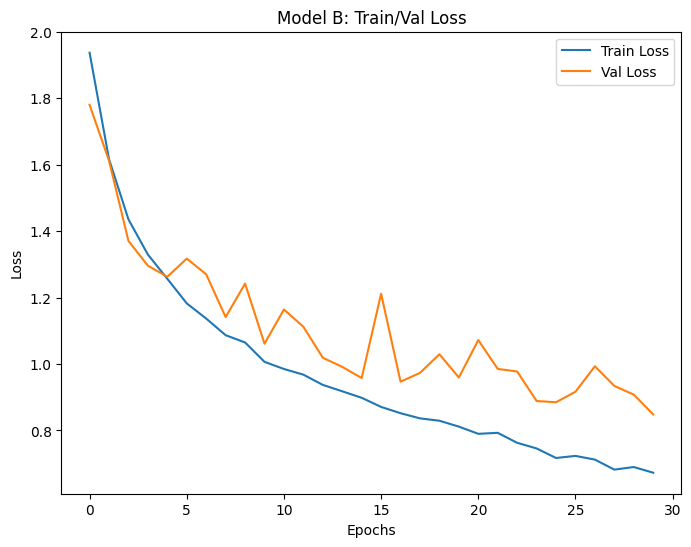

Model B Test Metrics - Acc: 0.6634, Precision: 0.6605, Recall: 0.6634
Epoch 1/30
----------
Epoch 2/30
----------
Epoch 3/30
----------
Epoch 4/30
----------
Epoch 5/30
----------
Epoch 6/30
----------
Epoch 7/30
----------
Epoch 8/30
----------
Epoch 9/30
----------
Epoch 10/30
----------
Epoch 11/30
----------
Epoch 12/30
----------
Epoch 13/30
----------
Epoch 14/30
----------
Epoch 15/30
----------
Epoch 16/30
----------
Epoch 17/30
----------
Epoch 18/30
----------
Epoch 19/30
----------
Epoch 20/30
----------
Epoch 21/30
----------
Epoch 22/30
----------
Epoch 23/30
----------
Epoch 24/30
----------
Epoch 25/30
----------
Epoch 26/30
----------
Epoch 27/30
----------
Epoch 28/30
----------
Epoch 29/30
----------
Epoch 30/30
----------

MobileNetV2 Params: 2235401 | Size: 8.66 MB
Training MobileNetV2...
Epoch 1/30
----------
Epoch 2/30
----------
Epoch 3/30
----------
Epoch 4/30
----------
Epoch 5/30
----------
Epoch 6/30
----------
Epoch 7/30
----------
Epoch 8/30
----------
Epoc

In [73]:
if __name__ == '__main__':
    criterion = nn.CrossEntropyLoss()
    EPOCHS = 30

    #  1. Custom Models
    model_a = Standard_Model(num_of_classes).to(device)
    model_b = LightWeightModel(num_of_classes).to(device)

    print(f"Model A (Standard) Params: {count_parameters(model_a)} | Size: {get_model_size_mb(model_a)*1024:.2f} KB")
    print(f"Model B (LightWeight) Params: {count_parameters(model_b)} | Size: {get_model_size_mb(model_b)*1024:.2f} KB")

    # Optimizer Selection for Model B
    opt_adam = optim.Adam(model_b.parameters(), lr=0.001)

    #------------------- below code is for check sgd optimizer

    # opt_sgd = optim.SGD(model_b.parameters(), lr=0.01)
    # opt_sgd_mom = optim.SGD(model_b.parameters(), lr=0.01, momentum=0.9)

    print("\nTraining Model B with Adam...")
    model_b_trained, history_b, time_b = train_model(model_b, dataloaders, criterion, opt_adam, num_of_epochs=EPOCHS)
    plot_history(history_b, "Model B: Train/Val Loss")

    acc_b, prec_b, rec_b,f1, cm_b = evaluate_model(model_b_trained, dataloaders['test'])
    print(f"Model B Test Metrics - Acc: {acc_b:.4f}, Precision: {prec_b:.4f}, Recall: {rec_b:.4f}")

    # Train Model A n
    opt_adam_a = optim.Adam(model_a.parameters(), lr=0.001)
    model_a_trained, history_a, time_a = train_model(model_a, dataloaders, criterion, opt_adam_a, num_of_epochs=EPOCHS)
    acc_a, prec_a, rec_a,f1, cm_a = evaluate_model(model_a_trained, dataloaders['test'])

    # Fine tuning
    mobilenet, efficientnet = get_sota_models(num_of_classes)
    mobilenet = mobilenet.to(device)
    efficientnet = efficientnet.to(device)

    print(f"\nMobileNetV2 Params: {count_parameters(mobilenet)} | Size: {get_model_size_mb(mobilenet):.2f} MB")

    opt_mb = optim.Adam(mobilenet.parameters(), lr=0.0001)
    print("Training MobileNetV2...")
    mobilenet_trained, history_mb, time_mb = train_model(mobilenet, dataloaders, criterion, opt_mb, num_of_epochs=EPOCHS)
    acc_mb, prec_mb, rec_mb,f1, cm_mb = evaluate_model(mobilenet_trained, dataloaders['test'])
    print(f"MobileNetV2 Test Accuracy: {acc_mb:.4f}")